In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split 
from joblib import dump, load
from tensorflow.keras.models import Model 
from tensorflow.keras.layers import Input, Dense
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [4]:
COLUMNS = ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 
           'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dnpkt', 'sjit', 'djit', 
           'swin', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 
           'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 
           'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 
           'is_sm_ips_ports', 'attack_cat', 'label']

file_list = ['UNSW-NB15_1.csv', 'UNSW-NB15_2.csv', 'UNSW-NB15_3.csv', 'UNSW-NB15_4.csv']
list_of_dfs = []

print("Start Merging Files")



try:
    for filename in file_list:
        df = pd.read_csv(filename, header=None, names=COLUMNS)
        list_of_dfs.append(df)
    
    combined_df = pd.concat(list_of_dfs, ignore_index=True)
    print(f"Merge all files successfully and the size is : {combined_df.shape}")
except FileNotFoundError:
    print(f" I can't find some file : {file_list}")
    raise

Start Merging Files
Merge all files successfully and the size is : (2540047, 43)


In [5]:
def preprocess_data(df):
    
    df.replace(['-', ' ', np.inf, -np.inf], np.nan, inplace=True) 
    df.drop(['id'], axis=1, inplace=True, errors='ignore') 

    categorical_features = ['proto', 'service', 'state']
    for col in categorical_features:
        if col in df.columns:
            df[col] = df[col].astype(str).astype('category').cat.codes
        
    feature_cols_temp = [col for col in df.columns if col not in ['label', 'attack_cat']]

    cols_to_keep = []
    for col in feature_cols_temp:
        df[col] = pd.to_numeric(df[col], errors='coerce') 
        if df[col].isna().all():
            print(f"   Warning the '{col}' Deleted completly because it was empty")
            df.drop(col, axis=1, inplace=True)
        else:
            cols_to_keep.append(col)    
    feature_cols_final = cols_to_keep
    df.dropna(subset=feature_cols_final, inplace=True)
    return df, feature_cols_final
    
combined_df_cleaned, feature_cols = preprocess_data(combined_df.copy())
print(f"The Size of Data after Cleanning: {combined_df_cleaned.shape}")


   Warning the 'sbytes' Deleted completly because it was empty
The Size of Data after Cleanning: (1087203, 41)


In [6]:
TEST_SIZE_RATIO = 0.3
SEED = 42
df_train_cleaned, df_test_cleaned = train_test_split(
    combined_df_cleaned, 
    test_size=TEST_SIZE_RATIO, 
    random_state=SEED, 
    shuffle=True,
    stratify=combined_df_cleaned['label'] 
)

print(f"The data has been split")
print(f"Size of Train Set (df_train_cleaned): {df_train_cleaned.shape}")
print(f"Size of Test Set (df_test_cleaned): {df_test_cleaned.shape}")

The data has been split
Size of Train Set (df_train_cleaned): (761042, 41)
Size of Test Set (df_test_cleaned): (326161, 41)


In [7]:
scaler = MinMaxScaler()

X_train_features = scaler.fit_transform(df_train_cleaned[feature_cols])
X_test_features = scaler.transform(df_test_cleaned[feature_cols])
X_train_df = pd.DataFrame(X_train_features, columns=feature_cols)
X_test_df = pd.DataFrame(X_test_features, columns=feature_cols)

dump(scaler, 'scaler_unsw_nb15.joblib')
print(" Saving MinMaxScaler Object gone just right")
train_labels = df_train_cleaned['label'].reset_index(drop=True)
X_train_ae = X_train_df[train_labels == 0].reset_index(drop=True) 

if X_train_ae.shape[0] > 1:
    X_train_ae, X_test_ae_val = train_test_split(X_train_ae, test_size=0.2, random_state=42)
else:
    X_test_ae_val = pd.DataFrame() 
    print("The number of natural samples are small for splliting")

y_train_cat_original = df_train_cleaned['attack_cat'].reset_index(drop=True)
y_test_cat_original = df_test_cleaned['attack_cat'].reset_index(drop=True)

print(f"Size of Autoencoder Train Data Set is: {X_train_ae.shape}")
print(f"Size of overall Train Data Set is: {X_train_df.shape}")
print(f"Size of overall Test Data Set is: {X_test_df.shape}")

 Saving MinMaxScaler Object gone just right
Size of Autoencoder Train Data Set is: (596393, 39)
Size of overall Train Data Set is: (761042, 39)
Size of overall Test Data Set is: (326161, 39)


In [8]:
print("Start Trainning Autoencoder")

input_dim = X_train_ae.shape[1] 

input_layer = Input(shape=(input_dim,))
encoder = Dense(128, activation='relu')(input_layer)
encoder = Dense(64, activation='relu')(encoder)
bottleneck = Dense(32, activation='relu')(encoder) # Bottel Neck
decoder = Dense(64, activation='relu')(bottleneck)
decoder = Dense(128, activation='relu')(decoder)
decoder_output = Dense(input_dim, activation='sigmoid')(decoder)

autoencoder = Model(inputs=input_layer, outputs=decoder_output)
autoencoder.compile(optimizer='adam', loss='mean_squared_error')

history_ae = autoencoder.fit(X_train_ae, X_train_ae,
                              epochs=50, 
                              batch_size=512,
                              shuffle=True,
                              validation_data=(X_test_ae_val, X_test_ae_val),
                              verbose=0) 

autoencoder.save('autoencoder_model.keras')
predictions_ae = autoencoder.predict(X_test_ae_val, verbose=0)
mse_ae = np.mean(np.power(X_test_ae_val - predictions_ae, 2), axis=1)
THRESHOLD = np.quantile(mse_ae, 0.95) 

print("Autoencoder Results")
print(f"Threshold is (THRESHOLD) Based on rebuild error : {THRESHOLD:.6f}")
print("Autoencoder Saved")

Start Trainning Autoencoder
Autoencoder Results
Threshold is (THRESHOLD) Based on rebuild error : 0.000027
Autoencoder Saved


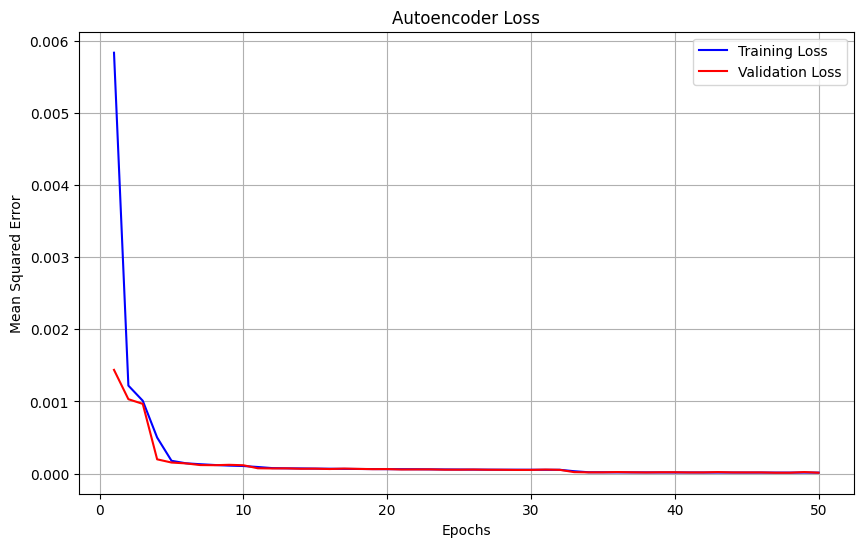

In [9]:
if 'history_ae' in locals():
    
    loss = history_ae.history['loss']
    val_loss = history_ae.history['val_loss']
    epochs = range(1, len(loss) + 1)
    plt.figure(figsize=(10, 6))
    plt.plot(epochs, loss, 'b', label='Training Loss')
    plt.plot(epochs, val_loss, 'r', label='Validation Loss')
    plt.title('Autoencoder Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Mean Squared Error')
    plt.legend()
    plt.grid(True)
    plt.show()

else:
    print("Some Error")

In [10]:
from tensorflow.keras.models import load_model
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
try:
    autoencoder = load_model('autoencoder_model.keras')
except:
    autoencoder = load_model('autoencoder_model.h5')

predictions_train = autoencoder.predict(X_train_df, verbose=0)
mse_train = np.mean(np.power(X_train_df - predictions_train, 2), axis=1)

predictions_test = autoencoder.predict(X_test_df, verbose=0)
mse_test = np.mean(np.power(X_test_df - predictions_test, 2), axis=1)

is_attack_train = (mse_train > THRESHOLD).astype(int)
is_attack_test = (mse_test > THRESHOLD).astype(int)

X_classifier_train = X_train_df[is_attack_train == 1].reset_index(drop=True)
y_classifier_train_cat = y_train_cat_original[is_attack_train == 1].reset_index(drop=True)

X_classifier_test = X_test_df[is_attack_test == 1].reset_index(drop=True)
y_classifier_test_cat = y_test_cat_original[is_attack_test == 1].reset_index(drop=True)

y_classifier_train_cat = y_classifier_train_cat[y_classifier_train_cat != 'Normal']
y_classifier_test_cat = y_classifier_test_cat[y_classifier_test_cat != 'Normal']

X_classifier_train = X_classifier_train.iloc[y_classifier_train_cat.index]
X_classifier_test = X_classifier_test.iloc[y_classifier_test_cat.index]

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_classifier_train_cat)
y_test_encoded = label_encoder.transform(y_classifier_test_cat)

y_train_one_hot = to_categorical(y_train_encoded)
y_test_one_hot = to_categorical(y_test_encoded)

dump(label_encoder, 'label_encoder_attacks.joblib')

print(f"Summarize the classifier data")
print(f"Classifier training data size : {X_classifier_train.shape}")
print(f" Number of attack categories coded: {len(label_encoder.classes_)}")
print(f"Kinds of discover attacks : {label_encoder.classes_}")

Summarize the classifier data
Classifier training data size : (52789, 39)
 Number of attack categories coded: 10
Kinds of discover attacks : [' Fuzzers' 'Analysis' 'Backdoors' 'DoS' 'Exploits' 'Generic'
 'Reconnaissance' 'Shellcode' 'Worms' nan]


In [11]:
# [18]: كود تدريب النموذج الهجين مع "موازنة الفئات" (Class Weights)
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Flatten
from sklearn.utils import class_weight
import numpy as np

print("Starting CNN + LSTM with Class Balancing...")

# 1. تجهيز أبعاد البيانات
N_FEATURES = X_classifier_train.shape[1]
X_train_cl_3d = X_classifier_train.values.reshape(X_classifier_train.shape[0], N_FEATURES, 1)
X_test_cl_3d = X_classifier_test.values.reshape(X_classifier_test.shape[0], N_FEATURES, 1)

num_classes = y_train_one_hot.shape[1]
input_shape = (N_FEATURES, 1)

# 2. حساب أوزان الفئات (الخطوة الجديدة والإضافية)
# -------------------------------------------------------
# نقوم بحساب الأوزان بناءً على البيانات: الفئة النادرة تأخذ وزناً كبيراً، والشائعة تأخذ وزناً صغيراً
class_weights_vals = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_encoded),
    y=y_train_encoded
)

# تحويل الأوزان إلى صيغة قاموس (Dictionary) يفهمها كيراس
class_weights_dict = dict(zip(np.unique(y_train_encoded), class_weights_vals))

print("Calculated Class Weights:")
for class_id, weight in class_weights_dict.items():
    # طباعة اسم الفئة ووزنها لنرى كيف سيتعامل معها النظام
    class_name = label_encoder.inverse_transform([class_id])[0]
    print(f"  {class_name}: {weight:.2f}")
# -------------------------------------------------------

# 3. بناء النموذج (نفس الهيكلية السابقة)
input_cl = Input(shape=input_shape)
conv = Conv1D(filters=64, kernel_size=3, activation='relu')(input_cl)
conv = Conv1D(filters=32, kernel_size=3, activation='relu')(conv)
lstm = LSTM(32, return_sequences=False)(conv)
dense = Dense(64, activation='relu')(lstm)
output_cl = Dense(num_classes, activation='softmax')(dense)

hybrid_classifier = Model(inputs=input_cl, outputs=output_cl)

hybrid_classifier.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 4. التدريب مع تمرير الأوزان (class_weight)
history_cl = hybrid_classifier.fit(
    X_train_cl_3d, y_train_one_hot,
    epochs=25,
    batch_size=512,
    validation_data=(X_test_cl_3d, y_test_one_hot),
    class_weight=class_weights_dict,  # <--- هنا تم وضع الأوزان
    verbose=1
)

hybrid_classifier.save('hybrid_classifier_model.keras')
print("Training Completed and Model Saved with Class Weights.")

Starting CNN + LSTM with Class Balancing...
Calculated Class Weights:
   Fuzzers: 1.60
  Analysis: 14.62
  Backdoors: 13.93
  DoS: 6.51
  Exploits: 1.40
  Generic: 1.02
  Reconnaissance: 4.80
  Shellcode: 35.91
  Worms: 329.93
  nan: 0.14
Epoch 1/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 12s 87ms/step - accuracy: 0.4780 - loss: 2.1132 - val_accuracy: 0.6594 - val_loss: 1.1749
Epoch 2/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 9s 85ms/step - accuracy: 0.6539 - loss: 1.7623 - val_accuracy: 0.6872 - val_loss: 0.9549
Epoch 3/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 9s 83ms/step - accuracy: 0.6263 - loss: 1.7073 - val_accuracy: 0.6164 - val_loss: 1.0989
Epoch 4/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 8s 80ms/step - accuracy: 0.7000 - loss: 1.6180 - val_accuracy: 0.7102 - val_loss: 0.9072
Epoch 5/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 8s 78ms/step - accuracy: 0.7317 - loss: 1.5414 - val_accuracy: 0.7695 - val_loss: 0.7676
Epoch 6/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 8s 78ms/step - accuracy: 0.7615 - loss: 1.4500 - val_accuracy: 0.7807 - val

In [12]:
from tensorflow.keras.models import load_model
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score
import numpy as np
import pandas as pd

print("Starting our Hybrid model (Optimized & Fixed Logic)")
try:
    autoencoder_model = load_model('autoencoder_model.keras')
except:
    autoencoder_model = load_model('autoencoder_model.h5')

try:
    hybrid_classifier = load_model('hybrid_classifier_model.keras')
except:
    hybrid_classifier = load_model('hybrid_classifier_model.h5')

le_object = load('label_encoder_attacks.joblib')
X_test_all = X_test_df.copy()
total_samples = len(X_test_all)
print(f"Total samples to process: {total_samples}")

print("1. Starting Batch Prediction using Autoencoder...")
predictions_test_ae = autoencoder_model.predict(X_test_all, batch_size=2048, verbose=1)

mse_test_all = np.mean(np.power(X_test_all.values - predictions_test_ae, 2), axis=1)
is_attack_test_all = (mse_test_all > THRESHOLD).astype(int)

# الخطوة الذكية: ننشئ مصفوفة مملوءة مسبقاً بكلمة "Normal"
# هذا يضمن عدم وجود قيم فارغة (nan) لأي عينة لم يكتشفها النظام كهجوم
y_pred_final = np.full(total_samples, "Normal", dtype=object)
attack_indices = np.where(is_attack_test_all == 1)[0]
print(f"2. Autoencoder detected {len(attack_indices)} potential attacks. Classifying them now...")

if len(attack_indices) > 0:
    X_attack_only = X_test_all.iloc[attack_indices]
    N_FEATURES = X_attack_only.shape[1]
    X_attack_3d = X_attack_only.values.reshape(X_attack_only.shape[0], N_FEATURES, 1)
    attack_prediction_prob = hybrid_classifier.predict(X_attack_3d, batch_size=1024, verbose=1)
    predicted_indices = np.argmax(attack_prediction_prob, axis=1)
    predicted_attack_names = le_object.inverse_transform(predicted_indices)
    y_pred_final[attack_indices] = predicted_attack_names

y_true_final = df_test_cleaned['attack_cat'].fillna('Normal').astype(str).values
y_pred_final = y_pred_final.astype(str)

print("\n\nFinal Performance Report for the Series Hybrid System (Fixed Logic)")
print("-" * 60)
print(classification_report(y_true_final, y_pred_final, zero_division=0))
acc = accuracy_score(y_true_final, y_pred_final)
print(f"Total Accuracy of our system: {acc * 100:.2f}%")

Starting our Hybrid model (Optimized & Fixed Logic)
Total samples to process: 326161
1. Starting Batch Prediction using Autoencoder...
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
2. Autoencoder detected 22716 potential attacks. Classifying them now...
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step


Final Performance Report for the Series Hybrid System (Fixed Logic)
------------------------------------------------------------
                precision    recall  f1-score   support

       Fuzzers       0.46      0.44      0.45      1522
      Analysis       0.10      0.43      0.16       155
     Backdoors       0.11      0.41      0.18       153
           DoS       0.09      0.03      0.04       348
      Exploits       0.72      0.51      0.59      1607
       Generic       0.97      0.89      0.93      2309
        Normal       1.00      0.95      0.97    319496
Reconnaissance       0.35      0.43      0.39       505
     Shellcode       0.05      0.37      0.09        59
         Worms     

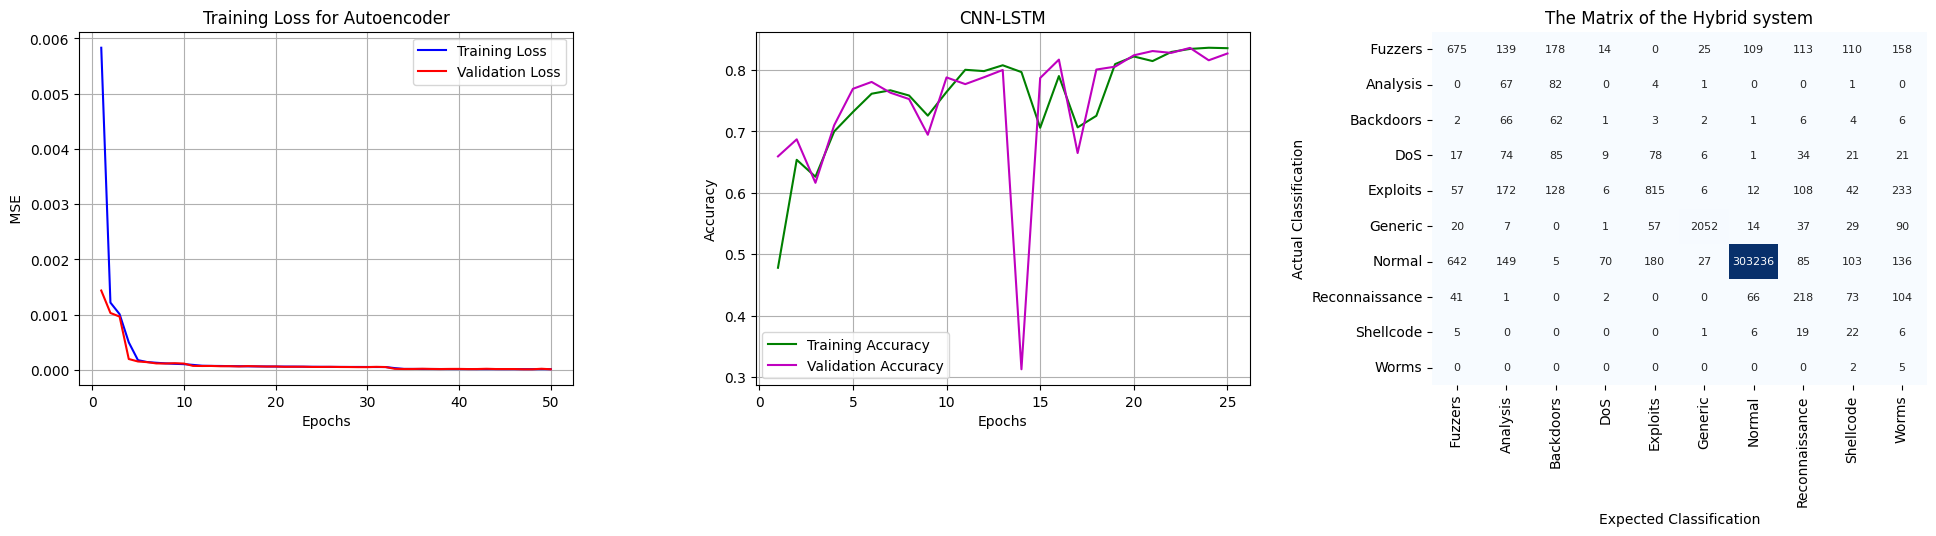

In [13]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

if 'history_ae' in locals():
    loss_ae = history_ae.history['loss']
    val_loss_ae = history_ae.history['val_loss']
    epochs = range(1, len(loss_ae) + 1)

    plt.figure(figsize=(20, 6))
    plt.subplot(1, 3, 1)
    plt.plot(epochs, loss_ae, 'b', label='Training Loss')
    plt.plot(epochs, val_loss_ae, 'r', label='Validation Loss')
    plt.title('Training Loss for Autoencoder')
    plt.xlabel('Epochs')
    plt.ylabel(' MSE ')
    plt.legend()
    plt.grid(True)
else:
    print("No Autoencoder Trainning Record (history_ae).")

if 'history_cl' in locals():
    acc_cl = history_cl.history['accuracy']
    val_acc_cl = history_cl.history['val_accuracy']
    epochs_cl = range(1, len(acc_cl) + 1)

    if len(acc_cl) > 0:
        plt.subplot(1, 3, 2)
        plt.plot(epochs_cl, acc_cl, 'g', label='Training Accuracy')
        plt.plot(epochs_cl, val_acc_cl, 'm', label='Validation Accuracy')
        plt.title('CNN-LSTM')
        plt.xlabel('Epochs')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.grid(True)
    else:
        print("The Hybrid Training Record (history_cl) Empty")
else:
    print("No Hybrid Training Record found (history_cl).")

if 'y_true_final' in locals() and 'y_pred_final' in locals() and len(y_true_final) > 0:

    labels = np.unique(y_true_final)
    cm = confusion_matrix(y_true_final, y_pred_final, labels=labels)
    cm_df = pd.DataFrame(cm, index=labels, columns=labels)

    plt.subplot(1, 3, 3)
    sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={"size": 8})
    plt.title('The Matrix of the Hybrid system')
    plt.xlabel('Expected Classification')
    plt.ylabel('Actual Classification')

    plt.tight_layout(pad=3.0)
    plt.savefig('hybrid_model_results.png')
    plt.show()

else:
    print("Can't Find the last Results (y_true_final و y_pred_final).")